# Wang Chong arXiv:2304.11864v2 #

## 计算单粒子能带H0 ##

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tqdm as tqdm
from quspin.basis import spinless_fermion_basis_1d
from quspin.operators import hamiltonian
from quspin.basis import spinless_fermion_basis_general
from quspin.tools.block_tools import block_diag_hamiltonian
import math as math
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import eigsh
import time

In [32]:
""" 转角 (unit in rad)"""
theta = np.radians(3.89)
""" MoTe2晶格常数 (unit in Angstrom) """
a0 = 3.52
""" moire晶格常数 (unit in Angstrom)"""
aM = a0 / (2 * np.sin(theta / 2)) 
"""原胞面积"""
A_cell= np.sqrt(3)/2 * aM**2 #unit in Angstrom^2
"""倒格矢量长度 (unit in Angstrom^-1)"""
bM = 4*np.pi/(np.sqrt(3)*aM) 
"""所有倒格矢量"""
angles = np.array([0, 1*np.pi/3, 2*np.pi/3, 3*np.pi/3, 4*np.pi/3, 5*np.pi/3]) 
b = bM * np.stack([np.cos(angles), np.sin(angles)], axis=1) 
"""moire周期势参数V和psi （V unit in eV, psi unit in rad）"""
V = 20.8e-3
psi = np.radians(107.7) 
"""平面波截断阶数"""
Nbloch = 7
dimBloch = 2*Nbloch + 1
"""有效质量m*和动能因子hbar^2/2m* (unit in eV·Angstrom^+2) """
m_star = 0.6
h2m = 3.8099 / m_star 
"""隧穿振幅 （unit in eV)"""
w = -23.8e-3 
"""高对称点晶格动量K_t,K_b"""
Kt = bM/np.sqrt(3) * np.stack([-np.cos(np.pi/6), +np.sin(np.pi/6)], axis=0) 
Kb = bM/np.sqrt(3) * np.stack([-np.cos(np.pi/6), -np.sin(np.pi/6)], axis=0) 

100%|██████████| 50/50 [00:17<00:00,  2.86it/s]


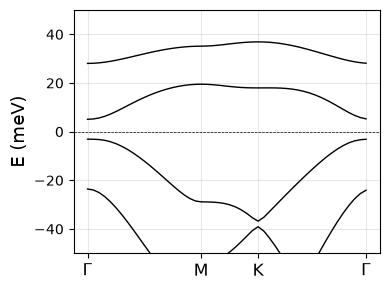

In [33]:
"""生成倒格子动量网格"""
G_lattice = np.array([m*b[0] + n*b[2] for m in range(-Nbloch, Nbloch+1) for n in range(-Nbloch, Nbloch+1)])
G_lattice_coord = np.array([(m,n) for m in range(-Nbloch, Nbloch+1) for n in range(-Nbloch, Nbloch+1)])
G_lattice_x = np.stack([1,0]) #b0方向的单位坐标
G_lattice_y = np.stack([0,1]) #b2方向的单位坐标
lenG = len(G_lattice)

def lattice_coord_to_index(m,n):
    return (m + Nbloch) * dimBloch + (n+Nbloch)
    
"""构造moire周期势 Delta_t/b """
Delta_1 = np.zeros((lenG, lenG), dtype=complex)
Delta_2 = np.zeros((lenG, lenG), dtype=complex)
b_allowed_coord = [G_lattice_x, G_lattice_y, -G_lattice_x-G_lattice_y]
for i, coord in enumerate(G_lattice_coord):
    for j, bj in enumerate(b_allowed_coord):
        coord_prime = coord + bj
        if -Nbloch <= coord_prime[0]<= Nbloch and  -Nbloch <= coord_prime[1] <= Nbloch:
            k = lattice_coord_to_index(coord_prime[0],coord_prime[1])
            Delta_1 [k,i] = V * np.exp(+1j * psi)
            Delta_2 [k,i] = V * np.exp(-1j * psi)
            
        coord_prime = coord - bj
        if -Nbloch <= coord_prime[0] <= Nbloch and  -Nbloch <= coord_prime[1] <= Nbloch:
            k = lattice_coord_to_index(coord_prime[0],coord_prime[1])
            Delta_1 [k,i] = V * np.exp(-1j * psi)
            Delta_2 [k,i] = V * np.exp(+1j * psi)
            
""" 构造隧穿矩阵T"""
T = np.zeros((lenG, lenG))
b_allowed_for_T = [G_lattice_x-G_lattice_x , G_lattice_y, G_lattice_x+G_lattice_y]
for i, coord in enumerate(G_lattice_coord):
    for j, bj in enumerate(b_allowed_for_T):
        coord_prime = coord - bj
        if -Nbloch <= coord_prime[0]<= Nbloch and  -Nbloch <= coord_prime[1] <= Nbloch:
            k = lattice_coord_to_index(coord_prime[0],coord_prime[1])
            T [k,i] = w
H0_non_diag = np.block([[Delta_1, T],[T.conj().T, Delta_2]])

"""计算H0中的动能项"""
def calc_H0_diag(k, Gs, Kt, Kb):
    # 我现在的基底是bloch平面波psi_i，我的每个基底在p算符下的动量为k->k+G_i
    diagts = []
    diagbs = []
    for i, Gi in enumerate(G_lattice):
        diagt = -h2m * (np.linalg.norm(k  + Gi - Kb)) **2
        diagb = -h2m * (np.linalg.norm(k  + Gi - Kt)) **2
        diagts.append(diagt)
        diagbs.append(diagb)
    H0diag = np.diag(diagts + diagbs)
    return H0diag

def calc_H0_eigs(k,Gs):
    H0_diag = calc_H0_diag(k,Gs,Kt,Kb)
    eval, evec = np.linalg.eigh(H0_diag + H0_non_diag)
    return eval,evec

"""对高对称点路径上每一个点进行对角化"""
def kpoints(start, end, n):
    return [start + i/n * (end - start) for i in range(n)]
    
G = np.array([0.0, 0.0])
M = bM * np.array([+1/2, 0.0])
Kplus = bM * np.array([-1/2, +1/(2*np.sqrt(3))])
Kminus = bM * np.array([-1/2, -1/(2*np.sqrt(3))])
Kp = bM * np.array([+1/2, -1/(2*np.sqrt(3))])
KK = bM * np.array([+1/2, +1/(2*np.sqrt(3))])

knum = np.array([10,5,10]) * 2
kpath = (kpoints(G,M,knum[0])+ kpoints(M, KK, knum[1]) + kpoints(KK, G, knum[2]))
kpath_label = [ r"$\Gamma$", "M", "K",  r"$\Gamma$"]

eigvals = []
for k in tqdm.tqdm(kpath):
    evals,evecs = calc_H0_eigs(k,G_lattice)
    eigvals.append(evals)
eigvals = np.array(eigvals) 

"""按照动量路径绘图"""
k_axis = np.arange(eigvals.shape[0])   
kticks = [0] + np.cumsum(knum).tolist()
kticks[-1] -= 1
band_num = eigvals.shape[1]   
E_min, E_max = -50, 50
plt.figure(figsize=(4, 3))

for n in range(band_num):
    E_n = eigvals[:, n] * 1000 
    if (E_min < E_n.max() and E_max > E_n.min()):
        plt.plot(k_axis, E_n , lw=1.0, color = 'k')
        
plt.xticks(kticks, kpath_label, fontsize=12)
plt.ylabel('E (meV)', fontsize=13)
plt.ylim(E_min, E_max)
plt.axhline(0, color='k', lw=0.5, ls='--')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
Ec = eigvals[:,-1]
print(f"W = {1000*(Ec.max()-Ec.min()):.1f}meV") #大约陈带的动能在8meV

W = 8.9meV


##  相互作用投影到陈带 ##

In [34]:
N1 = 4 #实空间30°方向的原胞数量
N2 = 6 #实空间-90°方向的原胞数量
N = N1*N2 #总采样数量
nu = 1/3
Ne = int(np.round(N * nu))
A = A_cell * N
band_id = -1 #chern带标记
e_square_div_epsilon_0 = 180.95 #(unit in e^2 * angstrom )
epsilonx2 = 8*2 #e^2 * tanh(|q|d)/(epsilon_0 * 2 * epsilon_r * |q|)
dist = 300 #(unit in Angstrom)

In [35]:
"""生成采样点"""
bias_x = 0
bias_y = 0
#这个ks是横向展开，G_lattice是纵向
ks = np.array([(j+bias_x)*b[0]/N1 + (i+bias_y)*b[2]/N2 for i in range(0,N2) for j in range(0,N1)])
kmesh = ks
kmesh = np.array(kmesh)
assert len(kmesh) == N #检查生成的采样点数量

"""计算每个k采样点上的单粒子波函数"""
kvecs = np.zeros((N,2*(dimBloch**2)), dtype = np.complex128)#每个采样点存一个波函数向量
keigs = np.zeros(N) #每个采样点的能量本征值
for i, k in enumerate(kmesh):
    eig, eigvec = calc_H0_eigs(k,G_lattice)
    kvecs[i,:] = eigvec[:,band_id]
    keigs[i] = eig[band_id]

"""计算库伦相互作用矩阵元"""
cons_e = e_square_div_epsilon_0 / epsilonx2 / A
def calc_cons_q(q):
    q_norm = np.linalg.norm(q)
    t = q_norm * dist
    tt= 1
    if t < 3: 
        tt = math.tanh(t)
    cons =  cons_e * tt / q_norm #cons大约在1-6meV之间
    return cons

#晶格动量的转移可以是两个对角格点相减，因此会是2倍大小的Gs
G_lattice_coord_extend = np.array([(m,n) for m in range(-2*Nbloch, 2*Nbloch+1) for n in range(-2*Nbloch, 2*Nbloch+1)])
G_lattice_extend = np.array([m*b[0] + n*b[2] for m in range(-2*Nbloch, 2*Nbloch+1) for n in range(-2*Nbloch, 2*Nbloch+1)])

def calc_interaction(kvecs,i,j,k,l):
    #限制q在一个mBZ中，如果q匹配成功，那么遍历所有的G,去匹配G
    # i -> k 匹配 j -> l
    k1 = kmesh[i]
    k2 = kmesh[j]
    k3 = kmesh[k]
    k4 = kmesh[l]
    if np.linalg.norm((k1 - k3) - (k4 - k2)) < 1e-6 and np.linalg.norm(k1 - k3) > 1e-6:
        #遍历所有的截断晶格向量
        V_int = 0
        for r, coord in enumerate(G_lattice_coord_extend): #k1 = k3 + q + G, k2 = k4 - q - G
            g = G_lattice_extend[r]
            F1 = calc_form_factor(kvecs[i,:],kvecs[k,:], coord)
            F2 = calc_form_factor(kvecs[j,:],kvecs[l,:], -coord)
            V_int += calc_cons_q(k1 - k3 + g) * F1 * F2
        return V_int
    else:
        return 0

def coord_to_index(x,y):
    idx = dimBloch*(x+Nbloch) + (y+Nbloch)
    return idx
    
def calc_form_factor(vec1,vec2,g_coord):
    #form factor需要按照层内匹配去计算
    x1 = max([-Nbloch + g_coord[0] , -Nbloch])
    x2 = min([+Nbloch + g_coord[0] , +Nbloch])
    y1 = max([-Nbloch + g_coord[1] , -Nbloch])
    y2 = min([+Nbloch + g_coord[1] , +Nbloch])
    
    form_factor = 0
    dbias = dimBloch**2
    for xi in range(x1,x2+1):
        for yi in range(y1,y2+1):
            c1 = coord_to_index(xi,yi)
            c2 = coord_to_index(xi-g_coord[0],yi-g_coord[1])
            c11 = c1 + dbias
            c21 = c2 + dbias
            form_factor_b  = vec1[c1].conj() * vec2[c2] #1层
            form_factor_t = vec1[c11].conj() * vec2[c21] #2层
            form_factor +=  (form_factor_b + form_factor_t)
    return form_factor
    
def calc_interaction_pairs(evecs):
    """规定产生算符是按照升序序号排列，湮灭算符是按照降序序号排列"""
    """ i -> k j -> l，i,j是需要湮灭的占据，k,l是产生的占据"""
    """ +V -> (l < k, i > j)"""
    V_pairs = []
    for i in tqdm.tqdm(range(1,N)):
        for j in range(0,i):
            #这里只规定ij的降序顺序，kl的顺序我不规定，因为有两种构型，需要区分费米子符号
            for k in range(0,N):
                for l in range(0,N):
                    if (l == k) or (l ==j) or (l == i) or (k == i) or (k == j) or ((k - i + l - j) != 0): #平行四边形这点很好判断，如果不是平行四边形就不成立
                        continue 
                    v = calc_interaction(evecs,i,j,k,l)
                    if v == 0:
                        continue
                    if k > l:
                        V_pairs.append([v,i,j,k,l]) #i -> k j ->l
                    else:
                        V_pairs.append([-v,i,j,k,l]) # k< l就是在挖掉ij的态上先生成左边的k再生成右边的l，l要越过k出现负号
    return V_pairs

V_pairs = calc_interaction_pairs(kvecs)
print()

100%|██████████| 23/23 [1:16:17<00:00, 199.03s/it]

## 按照总动量分块对角化 ##

In [36]:
basis = spinless_fermion_basis_1d(L=N, Nf=Ne)
print("basis dimension:", basis.Ns)  

r = np.arange(N1)
q = np.arange(N2)
N = N1*N2
k_table = np.array([(x,y) for y in q for x in r])
klen = len(k_table)
E_table = keigs -keigs.min()

def state_to_eig(idx):
    e = 0
    for j in range(N):
        bit = ((idx >> j) & 1)
        e +=  bit * E_table[N-j-1]
    return e
    
def state_to_coord(idx):
    coord = 0
    for j in range(N):
        bit = ((idx >> j) & 1)
        coord +=  bit * k_table[N-j-1]
    return (coord[0] % N1, coord[1] % N2)

#tags[i] 记录了K=i的所有态的集合
tags = []
for i in range(klen):
    tags.append([])

#对basis的总动量分类
for i in tqdm.tqdm(range(basis.Ns)):
    st = basis.states[i]
    coord = state_to_coord(st)
    coord_l = coord[0] + N1 * coord[1]
    tags[coord_l].append(st)

basis dimension: 735471


100%|██████████| 735471/735471 [02:53<00:00, 4245.59it/s] 


In [ ]:
eigs_tot = []
coo_block = []  
#遍历所有的动量块
for blk in tqdm.tqdm(range(klen)):
    rows = []
    cols = []
    data = []
    dic = {}
    #建立逆映射
    for idx, state in enumerate(tags[blk]):
        dic[state] = idx
        
    #遍历所有占据态
    for p, state in enumerate(tags[blk]):
        E_occ = state_to_eig(state)
        rows.append(p)
        cols.append(p)
        data.append(E_occ)

        #遍历V_pairs中的所有算符，V_pairs中已经规定了i>j，k和l的相对符号也确定了，只需要确定V的全局符号，依赖于ij，kl之间分别插入了多少个算符
        for V, i,j,k,l in V_pairs:
            z0 = (1 << (N-1))
            if ((z0 >> i) & state) > 0 and ((z0 >> j) & state) > 0 and ((z0 >> k) & state) == 0 and ((z0 >> l) & state) == 0 :
                pattern = (z0  >> i) + (z0 >> j) + (z0 >> k) +(z0 >> l)
                state_prime = state ^ pattern #散射出态
                state_res = state & state_prime #去掉算符的剩余占据项

                l1 = min(k,l)
                k1 = max(k,l) #k1 >l1
                global_sgn = ((state_res << (j+1)) >> ((j+1) + (N-i))) .bit_count() + ((state_res << (l1+1)) >> ((l1+1) + (N-k1))) .bit_count()
                V_tot = V * (-1)**global_sgn
                q = dic[state_prime]

                #print(f"in-state:{bin(state)}, out-state:{bin(state_prime)},{V_tot:.5f},{i}{j}{k}{l},{V:.5f},{global_sgn}")
                rows.append(p)
                cols.append(q)
                data.append(V_tot)
                
    sps = coo_matrix((data, (rows, cols)), shape=(len(tags[blk]), len(tags[blk])))
    eigs, _ = eigsh(sps, k=min(round(len(tags[blk])/2),12), which='SA')
    eigs_sorted = np.sort(eigs)
    eigs_tot.append(eigs_sorted)
    coo_block.append(sps)
    print(eigs_sorted*1000)

def plot_spectrum_block(es):
    points = []
    for i in range(len(es)):
        for j in range(len(es[i])):
            points.append((i,es[i][j]))
    Emin = min(j for _, j in points)
    print(E_min)
    points = np.array(points)
    
    k_vals = points[:, 0]
    E_vals = (points[:, 1] - Emin)*1000
    plt.figure(figsize=(5, 4))
    plt.scatter(k_vals, E_vals, s=5, c='b',label = fr"$\nu$=-1/3")
    plt.xlabel(r'$k_x + N_1 k_y$')
    plt.ylabel(r'$E -E_{GS}$ (meV)')
    plt.tight_layout()
    plt.legend(loc='upper right')
    plt.savefig("grid4x6_-1_3.png", dpi=300, bbox_inches='tight')  # 保存
    plt.show()
    
plot_spectrum_block(eigs_tot)

  4%|▍         | 1/24 [03:21<1:17:08, 201.22s/it]

[-49.03416292 -41.03974897 -40.83975427 -38.63775467 -37.61362009
 -35.92471108 -35.60300194 -34.58972895 -33.50683339 -33.41466044
 -33.37041738 -32.44152479]


  8%|▊         | 2/24 [06:51<1:15:46, 206.66s/it]

[-42.39624862 -37.89019565 -36.70416892 -35.89433298 -33.60380463
 -33.34659426 -32.35904707 -32.1758641  -31.39487033 -31.37305761
 -29.9656603  -29.57605468]


 12%|█▎        | 3/24 [10:07<1:10:34, 201.67s/it]

...

[-38.44116481 -38.27502436 -36.25381799 -36.10074697 -34.8512473
 -34.80470356 -34.27686614 -32.91084644 -31.4653463  -30.98598199
 -30.29083737 -30.14392363]


 67%|██████▋   | 16/24 [1:28:35<39:47, 298.44s/it]

[-37.1831699  -36.06450325 -35.49237753 -35.19349734 -34.29049163
 -33.90721054 -33.70241837 -33.50529806 -33.29625464 -33.286762
 -32.2067799  -31.36198134]


 71%|███████   | 17/24 [1:32:00<31:33, 270.53s/it]

[-47.63387667 -46.41459961 -39.05639887 -38.22172324 -36.88732073
 -36.01957445 -33.75900226 -33.58237293 -33.12479422 -32.37102063
 -31.97627529 -31.82493456]


In [159]:
#V_array记录所有形如 cl+ck+ci-cj-的相互作用算符 i>j 用来查找
#V_dict用来快速查找符合的形状
V_dict = {} 
V_array = np.zeros((N, N, N, N), dtype=np.complex128)
print(f"V_pairs:{len(V_pairs)}")
for V, i, j, k, l in tqdm.tqdm(V_pairs):
    V_dict[((1 << i) | (1 << j) | (1 << k) | (1 << l))] = 1
    V_array[i,j,k,l] = V

#对于某一个block K=i，两两态之间做xor
eigs_tot0 = []
coo_block0 = []
for i in tqdm.tqdm(range(klen)):
    rows = []
    cols = []
    data = []
    #print(f"momentum:{i} dim:{len(tags[i])}")

    ltags = len(tags[i])
    for p in range(len(tags[i])):
        
        #对角项
        E = state_to_eig(tags[i][p])
        rows.append(p)
        cols.append(p)
        data.append(E)
        
        for q in range(0,p):
            x = tags[i][p] ^ tags[i][q]
            if x.bit_count() == 4 and V_dict.get(x,0) != 0:
                t1 = []
                t2 = []
                for t in range(N):
                    tt = (1 << t)
                    if (tt & tags[i][p]) and ((tt & tags[i][q]) ==0) :
                        t1.append(N-1-t) #t1[1] 是 j t1[0] 是 i
                    if (tt & tags[i][q]) and ((tt & tags[i][p]) ==0):
                        t2.append(N-1-t)
                z = ((p << (t1[1]+1)) >>(t1[1]+1+N-t1[0])).bit_count()+((p << (t2[1]+1)) >> (t2[1]+1+N-t2[0])).bit_count()
                z = (-1)**z
                v_pq = z * (V_array[t1[0],t1[1],t2[0],t2[1]] + V_array[t1[0],t1[1],t2[1],t2[0]])
                rows.append(p)
                cols.append(q)
                #ij->kl如果合法，那么ij->lk也合法。我在V_pair时已经规定l<k为正序，V_pair中的符号已经是正确的了
                data.append(v_pq)
                rows.append(q)
                cols.append(p)
                data.append(v_pq.conj())
                
    sps = coo_matrix((data, (rows, cols)), shape=(len(tags[i]), len(tags[i])))
    eigs, _ = eigsh(sps, k=1, which='SA')
    eigs_sorted = np.sort(eigs)
    eigs_tot0.append(eigs_sorted)
    coo_block0.append(sps)
    print(eigs_sorted*1000)
                
def plot_spectrum_block(es):
    points = []
    for i in range(len(es)):
        for j in range(len(es[i])):
            points.append((i,es[i][j]))
    Emin = min(j for _, j in points)
    print(E_min)
    points = np.array(points)
    
    k_vals = points[:, 0]
    E_vals = (points[:, 1] - Emin)*1000
    plt.figure(figsize=(5, 4))
    plt.scatter(k_vals, E_vals, s=5, c='b',label = fr"$\nu$=-3/5")
    plt.xlabel(r'$k_x + N_1 k_y$')
    plt.ylabel(r'$E -E_{GS}$ (meV)')
    plt.tight_layout()
    plt.legend(loc='upper right')
    plt.show()
    
plot_spectrum_block(eigs_tot0)

V_pairs:20


  0%|          | 0/6 [00:00<?, ?it/s]


TypeError: Cannot use scipy.linalg.eig for sparse A with k >= N - 1. Use scipy.linalg.eig(A.toarray()) or reduce k.

In [51]:
np.savez('Grid_4x5_tMoTe2_nu_eq_3_5_eig.npz', Nbloch = Nbloch, nu = nu, eigs = eigs_tot)
np.savez('Grid_4x5_tMoTe2_nu_eq_3_5_coo.npz', Nbloch = Nbloch, nu = nu, coo = np.array(coo_block, dtype=object))

## 计算陈数 ##

100%|██████████| 26/26 [01:25<00:00,  3.27s/it]


chern_number -1.00000 band -1


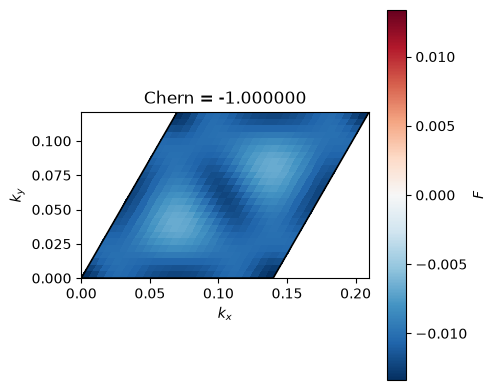

In [160]:
def calc_chern (bx, by, step, band_id):
    dbx = bx/step
    dby = by/step
    vecs = np.zeros((step+1, step+1, dim), dtype = complex)
    eband = np.zeros((step+1, step+1))
    for i in tqdm.tqdm(range(0,step+1)):
        for j in range(0,step+1):
            k = i * dbx + j * dby
            H0tot = H0_non_diag + calc_H0_diag(k, Gs, Kt, Kb)
            e , v = np.linalg.eigh(H0tot)
            vecs[i,j,:] = v[:,band_id]
            eband[i,j] = e[band_id]
    F = np.zeros((step,step))
    for i in range(0,step):
        for j in range(0,step):
            vs = [vecs[i,j,:], vecs[i+1,j,:],vecs[i+1,j+1,:],vecs[i,j+1,:]]   
            ua = np.vdot(vs[0],vs[1]) 
            ub = np.vdot(vs[1],vs[2])
            uc = np.vdot(vs[2],vs[3])
            ud = np.vdot(vs[3],vs[0])
            Zi = ua*ub*uc*ud
            F[i,j] = np.angle(Zi)
    return F

def plot_F(F, b0, b1, step):
    b0 = np.asarray(b0, dtype=float).reshape(2)
    b1 = np.asarray(b1, dtype=float).reshape(2)
    I, J = np.meshgrid(np.arange(step + 1), np.arange(step + 1), indexing='ij')
    X = I * (b0[0] / step) + J * (b1[0] / step)
    Y = I * (b0[1] / step) + J * (b1[1] / step)
    
    vmax = np.abs(F).max() or 1.0
    fig, ax = plt.subplots(figsize=(5, 4))
    mesh = ax.pcolormesh(X, Y, F.T, cmap='RdBu_r',
                         vmin=-vmax, vmax=vmax, shading='flat')

    corners = np.array([[0, 0], b0, b0 + b1, b1, [0, 0]])
    ax.plot(corners[:, 0], corners[:, 1], 'k-', lw=1.2)
    fig.colorbar(mesh, ax=ax, label=r'$F$')
    ax.set_aspect('equal')
    ax.set_xlabel(r'$k_x$'); ax.set_ylabel(r'$k_y$')
    ax.set_title(f'Chern = {F.sum()/(2*np.pi):.5f}')
    plt.tight_layout(); plt.show()

step = 25
band_id = -1
F = calc_chern(b[0], b[1], step, band_id)
ch = np.sum(F[:step, :step]) / (2 * np.pi)
print(f"chern_number {ch:.5f} band {band_id}")
plot_F(F,b[0],b[1], step)

##  H0的周期性 ##

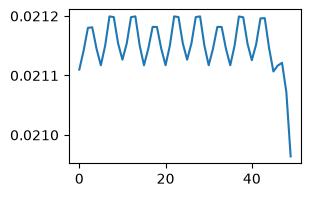

In [60]:
path = kpoints(-5*KK,5*KK,50)
etot = []
for  i,k in enumerate(path):
    H0 = H0_non_diag + calc_H0_diag(k, Gs, Kt, Kb)
    e,v = np.linalg.eigh(H0)
    etot.append(e[-1])
plt.figure(figsize=(3, 2))
plt.plot(etot)